# Example of using litstudy

This notebook shows an example of how to use `litstudy` from inside a Jupyter notebook. It shows how to load a dataset, plot statistics, perform topic modeling, do network analysis, and some more advanced features.

This notebook focuses on the topic of programming model for GPUs. GPUs (Graphic Processing Units) are specialized processors that are used in many data centers and supercomputers for data processing and machine learning. However, programming these devices remaining difficult, which is why there is a plethora of research on developing programming models for GPUs.

In [1]:
!pip install git+https://github.com/aliyaaar/litstudy.git

%pip install --force-reinstall "bibtexparser==1.4.4"


  Cloning https://github.com/aliyaaar/litstudy.git to /tmp/pip-req-build-xik8d52s
  Running command git clone --filter=blob:none --quiet https://github.com/aliyaaar/litstudy.git /tmp/pip-req-build-xik8d52s
  Resolved https://github.com/aliyaaar/litstudy.git to commit c3a0c91ac137298dc1641a4a1ec09dfed5e9c6af
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 112.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 27.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 108.2 MB/s  0:00:00
  Created wheel for litstudy: filename=litstudy-1.0.6-py3-none-any.whl size=50451 sha256=59e57561cb4d5da0fe50928485a553e08d081b6ed441a1ea35a79c63ad50e7f6
  Stored in directory: /tmp/pip-ephem-wheel-cache-flje6f79/wheels/38/4c/71/c4f2af6bde7682a27913458240ced06b3e10da85aeaf54802a
Successfully built litstudy
   ━━━━━━━━━━━━━━━

## Imports

In [2]:
# Import other libraries
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sbs
import bibtexparser
from bibtexparser.latexenc import latex_to_unicode
import litstudy

# Options for plots
plt.rcParams['figure.figsize'] = (10, 6)
sbs.set('paper')

# Import litstudy
path = os.path.abspath(os.path.join('..'))
if path not in sys.path:
    sys.path.append(path)

import litstudy

## Collecting the dataset

For this example, we have queried both IEEE Xplore and Springer Link for `"GPU" and "programming model"`. IEEE Xplore gives 5 CSV files (1 per page) and Springer Link gives a single CSV file. We load all files document sets and merge the resulting document sets.

In [6]:

# ==========================================
# LOAD DATA RIS FROM ZIP
# Adapted from NLeSC/litstudy GitHub
# ==========================================

import litstudy
from pathlib import Path
from zipfile import ZipFile
import shutil

# 1. Nama file ZIP
nama_zip = "mtl.zip"

# 2. Cari ZIP di Google Colab
zip_path = Path("/content") / nama_zip

# Jika tidak ada, ambil dari Google Drive
if not zip_path.exists():
    from google.colab import drive
    drive.mount("/content/drive")
    zip_path = Path("/content/drive/MyDrive") / nama_zip

if not zip_path.exists():
    raise FileNotFoundError(
        "File ZIP tidak ditemukan. "
        "Upload ZIP ke My Drive terlebih dahulu."
    )

# 3. Ekstrak ZIP
folder = Path("/content/data_slr")

if folder.exists():
    shutil.rmtree(folder)

folder.mkdir(parents=True)

with ZipFile(zip_path, "r") as z:
    z.extractall(folder)

# 4. Cari semua file RIS
ris_files = sorted(
    p for p in folder.rglob("*")
    if p.is_file() and p.suffix.lower() == ".ris"
)

print("File RIS ditemukan:", len(ris_files))

# 5. Kelompokkan berdasarkan database
kelompok = {
    "IEEE": [],
    "Scopus": [],
    "Taylor & Francis": []
}

for path in ris_files:
    nama = str(path.relative_to(folder)).lower()

    if "ieee" in nama:
        kelompok["IEEE"].append(path)
    elif "scopus" in nama:
        kelompok["Scopus"].append(path)
    elif "taylor" in nama or "francis" in nama:
        kelompok["Taylor & Francis"].append(path)
    else:
        raise ValueError(f"Sumber tidak dikenali: {path}")

# 6. Load RIS menggunakan LitStudy
hasil = {}

for sumber, daftar_file in kelompok.items():

    gabungan = litstudy.DocumentSet([])

    for path in daftar_file:
        data = litstudy.load_ris_file(str(path))
        gabungan = gabungan + data

    hasil[sumber] = gabungan

# 7. Variabel setiap database
docs_ieee = hasil["IEEE"]
docs_scopus = hasil["Scopus"]
docs_taylor = hasil["Taylor & Francis"]

print("\n===== ARTIKEL PER DATABASE =====")
print(len(docs_ieee), "papers loaded from IEEE")
print(len(docs_scopus), "papers loaded from Scopus")
print(len(docs_taylor), "papers loaded from Taylor & Francis")

# 8. Gabungkan artikel seperti GitHub
docs_awal = docs_ieee + docs_scopus + docs_taylor

# Operator | menggabungkan tanpa duplikasi
docs = docs_ieee | docs_scopus | docs_taylor

# 9. Hasil penggabungan
print("\n===== HASIL PENGGABUNGAN =====")
print("Total artikel awal:", len(docs_awal))
print("Total artikel duplikasi:", len(docs_awal) - len(docs))
print("Total artikel setelah duplikasi dihapus:", len(docs))

# 10. Periksa abstrak sebelum topic modeling
docs_nlp = docs.filter_docs(
    lambda d: bool(d.abstract and d.abstract.strip())
)

print("\n===== KESIAPAN TOPIC MODELING =====")
print("Artikel dengan abstrak:", len(docs_nlp))
print("Artikel tanpa abstrak:", len(docs) - len(docs_nlp))
print("\nData siap untuk analisis LitStudy!")


Mounted at /content/drive


File RIS ditemukan: 4

===== ARTIKEL PER DATABASE =====
7 papers loaded from IEEE
105 papers loaded from Scopus
40 papers loaded from Taylor & Francis

===== HASIL PENGGABUNGAN =====
Total artikel awal: 152
Total artikel duplikasi: 0
Total artikel setelah duplikasi dihapus: 152

===== KESIAPAN TOPIC MODELING =====
Artikel dengan abstrak: 109
Artikel tanpa abstrak: 43

Data siap untuk analisis LitStudy!


We can also exclude some papers that we are not interested in. Here, we load a document set from a RIS file and subtract these documents from our original document set.

The amount metadata provided by the CSV files is minimal. To enhance the metadata, we can find the corresponding articles on Scopus using `refine_scopus`. This function returns two sets: the set of documents that were found on Scopus and the set of original documents not were not found. We have two options on how to handle these two sets: (1) merge the two sets back into one set or (2) discard the documents that were not found. We chose the second option here for simplicity.

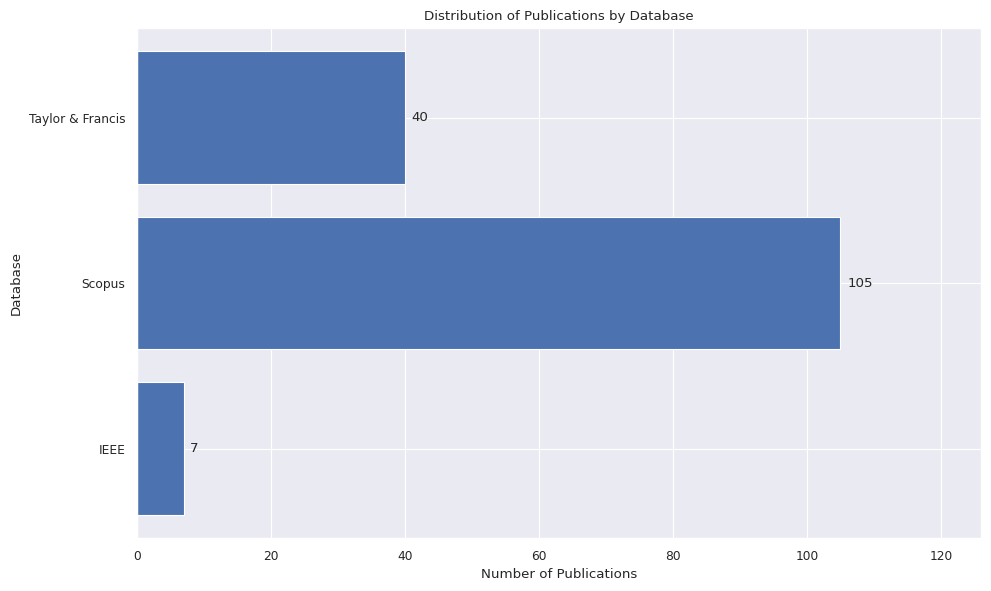

Total artikel: 152


In [12]:

import matplotlib.pyplot as plt

# Jumlah artikel dari masing-masing database
database = ["IEEE", "Scopus", "Taylor & Francis"]

jumlah = [
    len(docs_ieee),
    len(docs_scopus),
    len(docs_taylor)
]

# Membuat grafik balok
plt.figure(figsize=(10, 6))

bars = plt.barh(database, jumlah)

# Menampilkan angka pada setiap balok
for bar in bars:
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height()/2,
        str(int(bar.get_width())),
        va="center"
    )

plt.title("Distribution of Publications by Database")
plt.xlabel("Number of Publications")
plt.ylabel("Database")

plt.xlim(0, max(jumlah) * 1.2)
plt.tight_layout()
plt.show()

print("Total artikel:", sum(jumlah))


Total artikel: 152
Artikel dengan tahun: 152


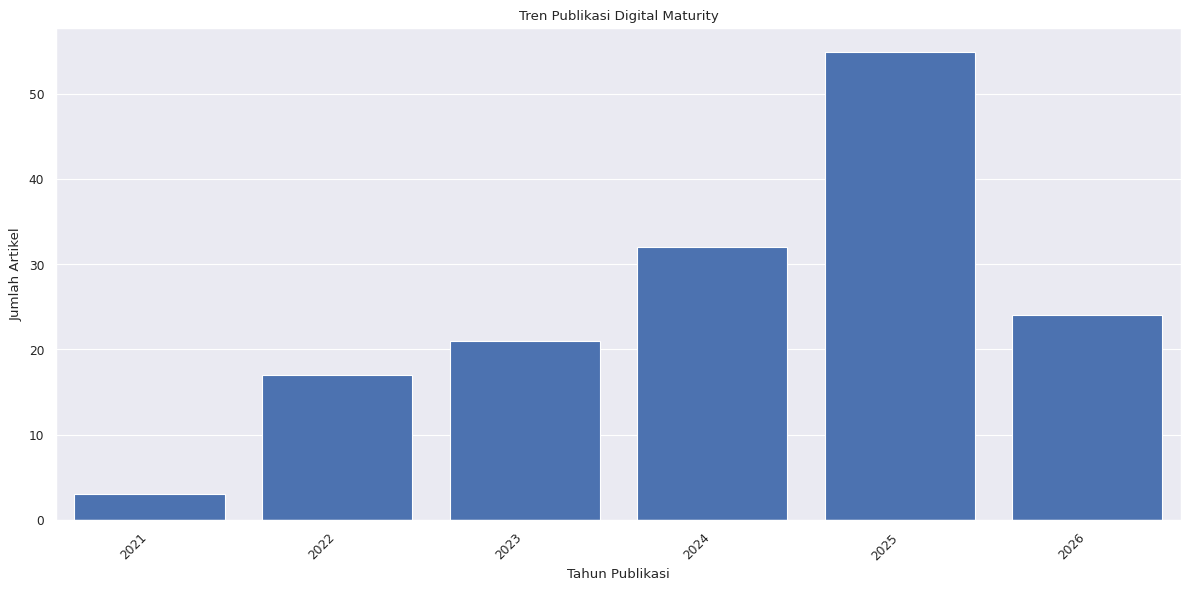

In [10]:

import litstudy
import matplotlib.pyplot as plt

# Gunakan semua artikel dari ZIP
data = docs

# Periksa data tahun
tahun_valid = [
    d.publication_year
    for d in data
    if d.publication_year is not None
]

print("Total artikel:", len(data))
print("Artikel dengan tahun:", len(tahun_valid))

if tahun_valid:
    plt.figure(figsize=(12, 6))

    litstudy.plot_year_histogram(
        data,
        vertical=True
    )

    plt.title("Tren Publikasi Digital Maturity")
    plt.xlabel("Tahun Publikasi")
    plt.ylabel("Jumlah Artikel")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Grafik kosong karena metadata tahun tidak tersedia.")


Next, we plot the number of documents per publication source.

In [15]:

# TEXT PREPROCESSING

import litstudy

docs_nlp = docs.filter_docs(
    lambda d: bool(
        d.abstract and d.abstract.strip()
    )
)

print("Total artikel:", len(docs))
print("Artikel dengan abstrak:", len(docs_nlp))
print("Artikel tanpa abstrak:", len(docs)-len(docs_nlp))

# Membuat corpus
corpus = litstudy.build_corpus(
    docs_nlp,
    ngram_threshold=0.8
)

print("Corpus berhasil dibuat.")


Total artikel: 152
Artikel dengan abstrak: 109
Artikel tanpa abstrak: 43
Corpus berhasil dibuat.


,count
development,53
supply_chain,52
effective,51
maturity,51
improve,49
practical,44
analysis,42
enhance,40
framework,40
design,40


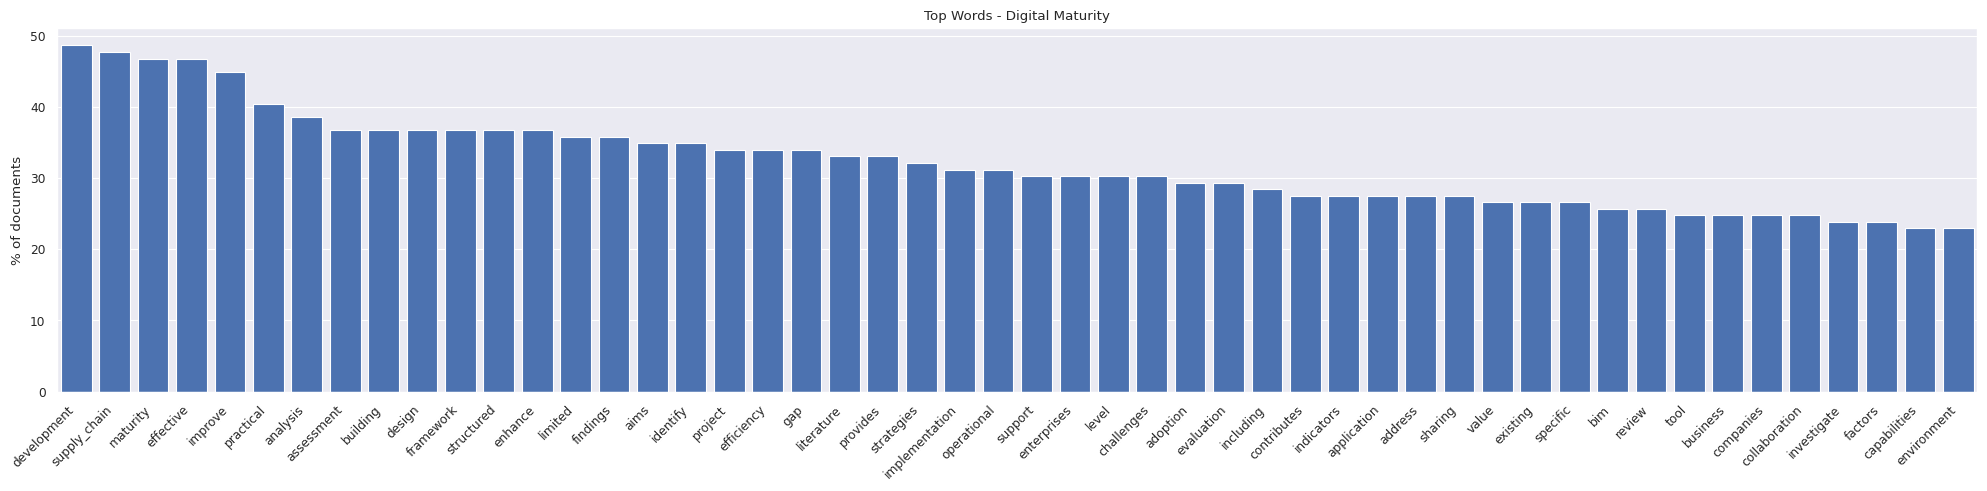

In [16]:

import matplotlib.pyplot as plt

# Tabel distribusi kata
word_dist = litstudy.compute_word_distribution(corpus)

display(
    word_dist.sort_values(
        "count", ascending=False
    ).head(30)
)

# Grafik 50 kata dominan
plt.figure(figsize=(20, 5))

litstudy.plot_word_distribution(
    corpus,
    limit=50,
    title="Top Words - Digital Maturity",
    vertical=True,
    label_rotation=45
)

plt.tight_layout()
plt.show()


In [18]:

# NMF TOPIC MODELING

num_topics = 8

topic_model = litstudy.train_nmf_model(
    corpus,
    num_topics,
    max_iter=250
)

# Menampilkan kata dominan tiap topik
for i in range(num_topics):
    print(
        f"Topic {i+1}:",
        topic_model.best_tokens_for_topic(i)
    )


Topic 1: ['bim', 'technical', 'mechanism', 'building', 'enabled']
Topic 2: ['sharing', 'risks', 'game', 'cost', 'network']
Topic 3: ['sector', 'semantic', 'complexity', 'project', 'interoperability']
Topic 4: ['blockchain', 'iot', 'automation', 'security', 'traceability']
Topic 5: ['maturity', 'assessment', 'firms', 'success', 'organizations']
Topic 6: ['companies', 'maturity', 'manufacturing', 'framework', 'roadmap']
Topic 7: ['smes', 'maturity', 'small', 'medium', 'small_medium']
Topic 8: ['performance', 'supply_chain', 'sustainable', 'procurement', 'collaboration']


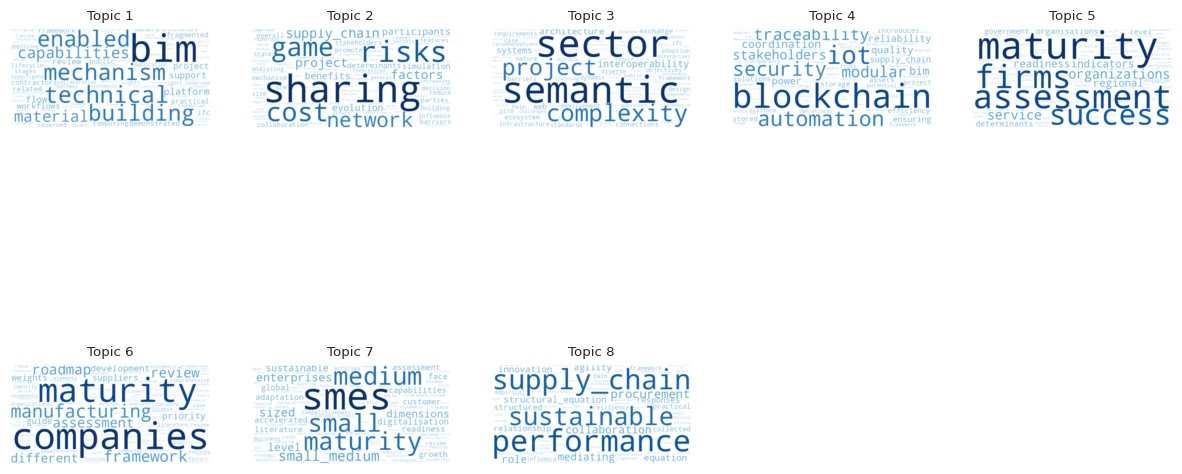

In [19]:

# TOPIC WORD CLOUDS

plt.figure(figsize=(15, 8))

litstudy.plot_topic_clouds(
    topic_model,
    ncols=5
)

plt.show()


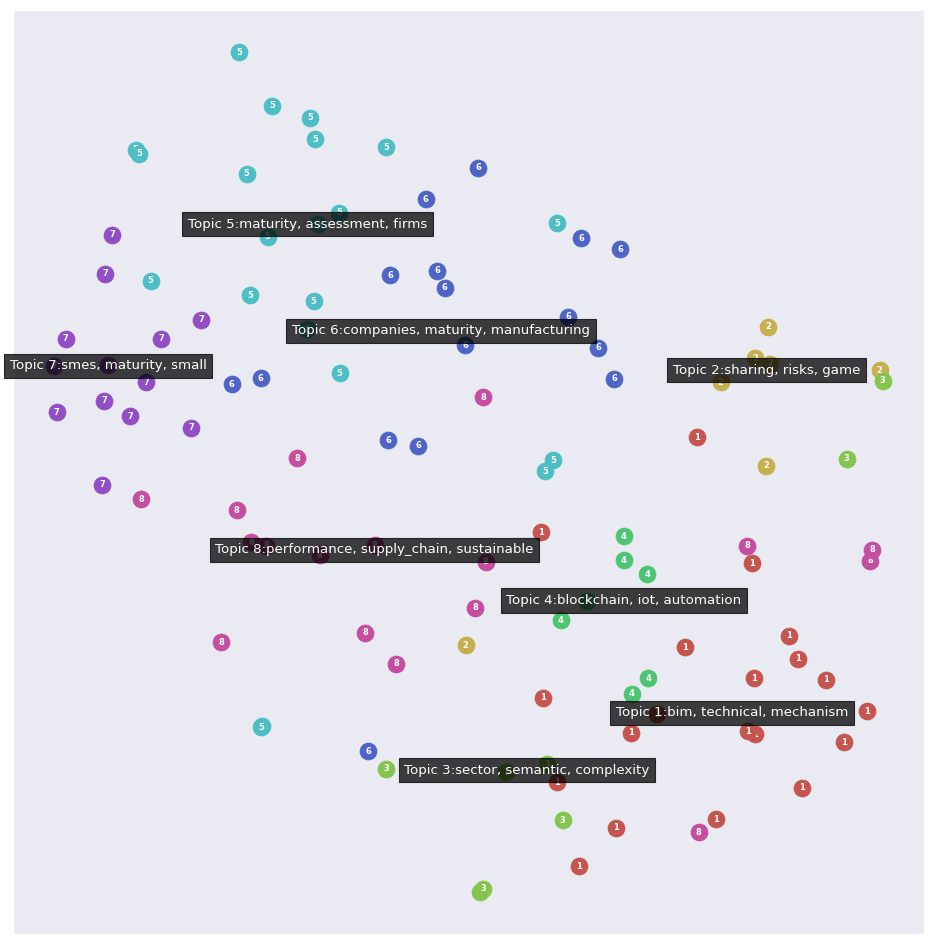

In [20]:

# TOPIC LANDSCAPE

plt.figure(figsize=(16, 12))

litstudy.plot_embedding(
    corpus,
    topic_model
)

plt.show()


In [21]:

# ADVANCED TOPIC MODELING

for i in range(num_topics):

    print(f"\n===== TOPIC {i+1} =====")
    print(topic_model.best_tokens_for_topic(i))

    doc_ids = topic_model.best_documents_for_topic(
        i,
        limit=5
    )

    for doc_id in doc_ids:
        print("-", docs_nlp[int(doc_id)].title)



===== TOPIC 1 =====
['bim', 'technical', 'mechanism', 'building', 'enabled']
- Integrating BIM and GIS Data to Support the Building Management
- BUILDING INFORMATION MODELLING (BIM) INTEGRATION CAPABILITIES FOR SUPPLY CHAIN INTEGRATION IN CONSTRUCTION: A SYSTEMATIC REVIEW
- Modeling the determinants of BIM-enabled integration and collaboration
- Mechanism to motivate information sharing behavior on the BIM platform for construction projects
- BIM-Enabled Supply Chain Integration in Offsite Construction: Practices and Technical Mechanisms

===== TOPIC 2 =====
['sharing', 'risks', 'game', 'cost', 'network']
- Game-Theoretic Analysis of Information Sharing Evolution and Stability in Digital Supply Chains
- Intelligent construction technology based information sharing network for prefabricated building supply chain: a social network analysis approach
- Research on evolutionary game and efficiency improvement of construction supply chain based on information sharing
- Research on Evolution

In [23]:
for i in range(num_topics):
    print(f"\nTOPIC {i+1}")
    print(topic_model.best_tokens_for_topic(i))


TOPIC 1
['bim', 'technical', 'mechanism', 'building', 'enabled']

TOPIC 2
['sharing', 'risks', 'game', 'cost', 'network']

TOPIC 3
['sector', 'semantic', 'complexity', 'project', 'interoperability']

TOPIC 4
['blockchain', 'iot', 'automation', 'security', 'traceability']

TOPIC 5
['maturity', 'assessment', 'firms', 'success', 'organizations']

TOPIC 6
['companies', 'maturity', 'manufacturing', 'framework', 'roadmap']

TOPIC 7
['smes', 'maturity', 'small', 'medium', 'small_medium']

TOPIC 8
['performance', 'supply_chain', 'sustainable', 'procurement', 'collaboration']


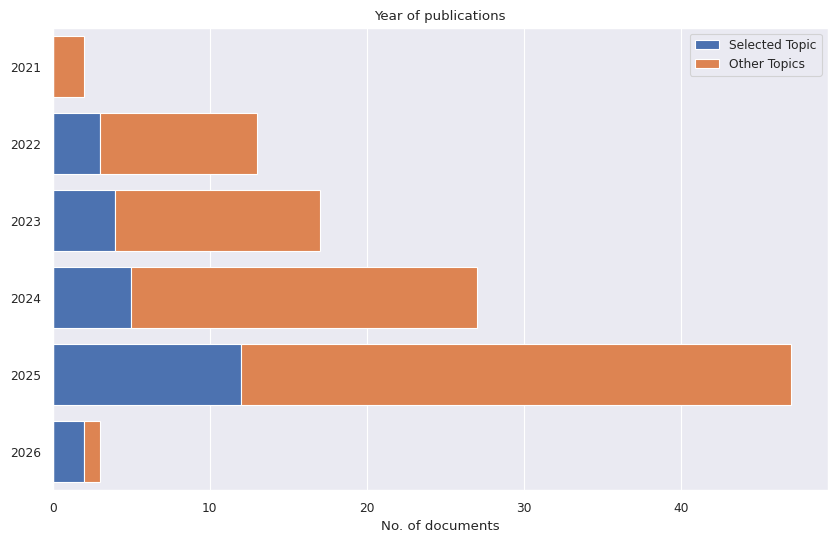

,Selected Topic,Other Topics
2021,0.00,100.00
2022,23.08,76.92
2023,23.53,76.47
2024,18.52,81.48
2025,25.53,74.47
2026,66.67,33.33


In [22]:

# TOPIC DEVELOPMENT BY YEAR

topic_id = 0
threshold = 0.2

selected = (
    topic_model.doc2topic[:, topic_id] > threshold
)

docs_topic = docs_nlp.add_property(
    "selected_topic",
    selected
)

groups = {
    "Selected Topic": "selected_topic",
    "Other Topics": "not selected_topic"
}

litstudy.plot_year_histogram(
    docs_topic,
    groups=groups,
    stacked=True
)

plt.show()

# Tabel persentase
table = litstudy.compute_year_histogram(
    docs_topic,
    groups=groups
)

display(
    (table.div(table.sum(axis=1), axis=0) * 100).round(2)
)
